# Regression

### Predict future values based on historical data.

In this course, we will explore regression algorithms in depth. We will develop a machine learning model to predict car prices and aim to achieve an accuracy of over 85%.

In [4]:
%%capture
pip install xlrd==2.0.1

### Readind Data

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
ls # Lists the files and directories in the current directory.

Day3-Regression.ipynb  cars.json              kc_house_data.csv
Untitled.ipynb         cars.xls
cars.db                cars.xlsx


In [100]:
pwd # Displays the full path of the current working directory.

'/Users/nbarcin/Documents/AI/day3'

In [6]:
conn=sqlite3.connect('cars.db')

In [7]:
df=pd.read_sql_query('select * from cars',conn)

In [8]:
df.head()

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
0,17314.103129,8221.0,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,1
1,17542.036083,9135.0,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
2,16218.847862,13196.0,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
3,16336.913140,16342.0,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,0
4,16339.170324,19832.0,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,1


In [10]:
df1=pd.read_json('cars.json')

In [11]:
df1.head()

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
0,17314.103129,8221,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,1
1,17542.036083,9135,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
2,16218.847862,13196,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
3,16336.913140,16342,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,0
4,16339.170324,19832,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,1


In [14]:
df2=pd.read_excel('cars.xlsx') #sheet_name=''

In [15]:
df2.head()

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
0,17314.103129,8221,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,1
1,17542.036083,9135,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
2,16218.847862,13196,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
3,16336.913140,16342,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,0
4,16339.170324,19832,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,1


### EDA Exploratory Data Analysis

In [17]:
df.head() #first 5 rows

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
0,17314.103129,8221,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,1
1,17542.036083,9135,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
2,16218.847862,13196,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
3,16336.913140,16342,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,0
4,16339.170324,19832,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,1


In [19]:
df.tail() #last 5 rows

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
799,16507.070267,16229,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,0,0
800,16175.957604,19095,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
801,15731.132897,20484,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
802,15118.893228,25979,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
803,13585.636802,35662,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,0,0


In [21]:
df.shape #row,column

(804, 12)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 804 entries, 0 to 803
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Price     804 non-null    float64
 1   Mileage   804 non-null    int64  
 2   Make      804 non-null    object 
 3   Model     804 non-null    object 
 4   Trim      804 non-null    object 
 5   Type      804 non-null    object 
 6   Cylinder  804 non-null    int64  
 7   Liter     804 non-null    float64
 8   Doors     804 non-null    int64  
 9   Cruise    804 non-null    int64  
 10  Sound     804 non-null    int64  
 11  Leather   804 non-null    int64  
dtypes: float64(2), int64(6), object(4)
memory usage: 81.7+ KB


In [25]:
df.isnull().sum() #How many missing values are there in each column?

Price       0
Mileage     0
Make        0
Model       0
Trim        0
Type        0
Cylinder    0
Liter       0
Doors       0
Cruise      0
Sound       0
Leather     0
dtype: int64

In [26]:
df.isna().sum()

Price       0
Mileage     0
Make        0
Model       0
Trim        0
Type        0
Cylinder    0
Liter       0
Doors       0
Cruise      0
Sound       0
Leather     0
dtype: int64

In [28]:
df.describe() #Statistics

,Price,Mileage,Cylinder,Liter,Doors,Cruise,Sound,Leather
count,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000
mean,21343.143767,19831.934080,5.268657,3.037313,3.527363,0.752488,0.679104,0.723881
std,9884.852801,8196.319707,1.387531,1.105562,0.850169,0.431836,0.467111,0.447355
min,8638.930895,266.000000,4.000000,1.600000,2.000000,0.000000,0.000000,0.000000
25%,14273.073870,14623.500000,4.000000,2.200000,4.000000,1.000000,0.000000,0.000000
50%,18024.995019,20913.500000,6.000000,2.800000,4.000000,1.000000,1.000000,1.000000
75%,26717.316636,25213.000000,6.000000,3.800000,4.000000,1.000000,1.000000,1.000000
max,70755.466717,50387.000000,8.000000,6.000000,4.000000,1.000000,1.000000,1.000000


In [30]:
df.corr(numeric_only=True) #Calculates the correlation between numerical columns only.

,Price,Mileage,Cylinder,Liter,Doors,Cruise,Sound,Leather
Price,1.000000,-0.143051,0.569086,0.558146,-0.138750,0.430851,-0.124348,0.157197
Mileage,-0.143051,1.000000,-0.029461,-0.018641,-0.016944,0.025037,-0.026146,0.001005
Cylinder,0.569086,-0.029461,1.000000,0.957897,0.002206,0.354285,-0.089704,0.075520
Liter,0.558146,-0.018641,0.957897,1.000000,-0.079259,0.377509,-0.065527,0.087332
Doors,-0.138750,-0.016944,0.002206,-0.079259,1.000000,-0.047674,-0.062530,-0.061969
Cruise,0.430851,0.025037,0.354285,0.377509,-0.047674,1.000000,-0.091730,-0.070573
Sound,-0.124348,-0.026146,-0.089704,-0.065527,-0.062530,-0.091730,1.000000,0.165444
Leather,0.157197,0.001005,0.075520,0.087332,-0.061969,-0.070573,0.165444,1.000000


<Axes: >

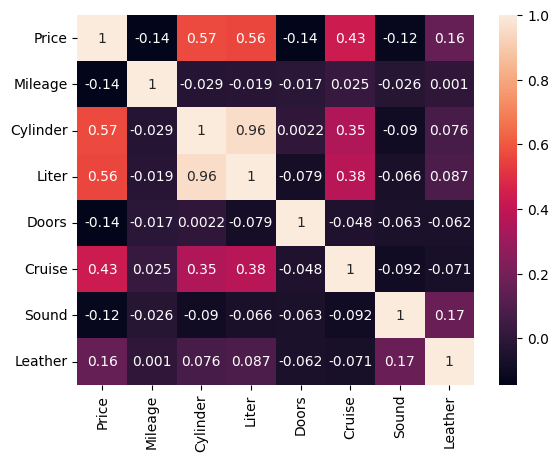

In [33]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [34]:
df['Make'].unique()

array(['Buick', 'Cadillac', 'Chevrolet', 'Pontiac', 'SAAB', 'Saturn'],
      dtype=object)

In [35]:
df['Make'].value_counts()

Make
Chevrolet    320
Pontiac      150
SAAB         114
Buick         80
Cadillac      80
Saturn        60
Name: count, dtype: int64

In [36]:
df['Make'].value_counts(normalize=True)

Make
Chevrolet    0.398010
Pontiac      0.186567
SAAB         0.141791
Buick        0.099502
Cadillac     0.099502
Saturn       0.074627
Name: proportion, dtype: float64

In [37]:
df[df['Make']=='Cadillac']

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
80,51154.047216,2202,Cadillac,CST-V,Sedan 4D,Sedan,8,5.7,4,1,1,1
81,49248.158967,6685,Cadillac,CST-V,Sedan 4D,Sedan,8,5.7,4,1,0,1
82,46747.673270,15343,Cadillac,CST-V,Sedan 4D,Sedan,8,5.7,4,1,1,1
83,44130.617055,21341,Cadillac,CST-V,Sedan 4D,Sedan,8,5.7,4,1,0,1
84,44084.914212,21367,Cadillac,CST-V,Sedan 4D,Sedan,8,5.7,4,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
155,63913.117248,18200,Cadillac,XLR-V8,Hardtop Conv 2D,Convertible,8,4.6,2,1,1,1
156,60567.549093,23193,Cadillac,XLR-V8,Hardtop Conv 2D,Convertible,8,4.6,2,1,1,1
157,57154.443437,29260,Cadillac,XLR-V8,Hardtop Conv 2D,Convertible,8,4.6,2,1,1,1
158,55639.087654,31805,Cadillac,XLR-V8,Hardtop Conv 2D,Convertible,8,4.6,2,1,0,1


In [38]:
df[df['Price']>4000]

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
0,17314.103129,8221,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,1
1,17542.036083,9135,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
2,16218.847862,13196,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
3,16336.913140,16342,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,0
4,16339.170324,19832,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
799,16507.070267,16229,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,0,0
800,16175.957604,19095,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
801,15731.132897,20484,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
802,15118.893228,25979,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0


### Data Visualization

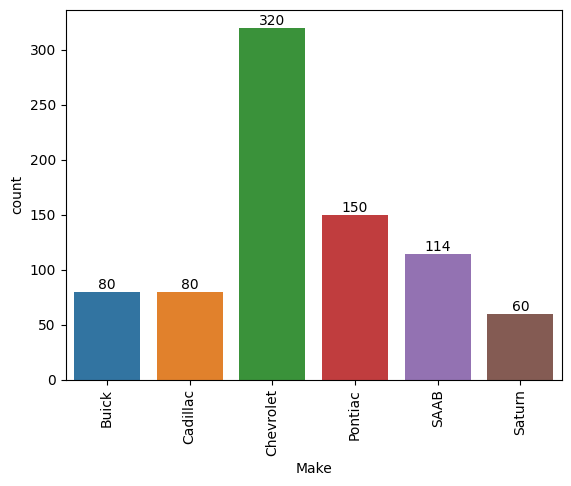

In [48]:
ax = sns.countplot(x=df['Make'], hue=df['Make'])
for container in ax.containers:
    ax.bar_label(container)
plt.xticks(rotation=90)
plt.show()

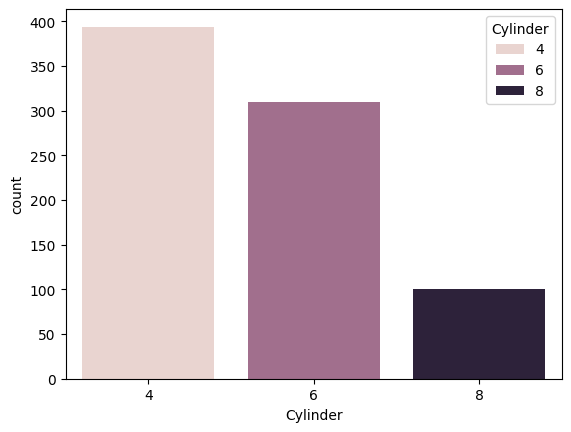

In [49]:
sns.countplot(x=df['Cylinder'],hue=df['Cylinder']);

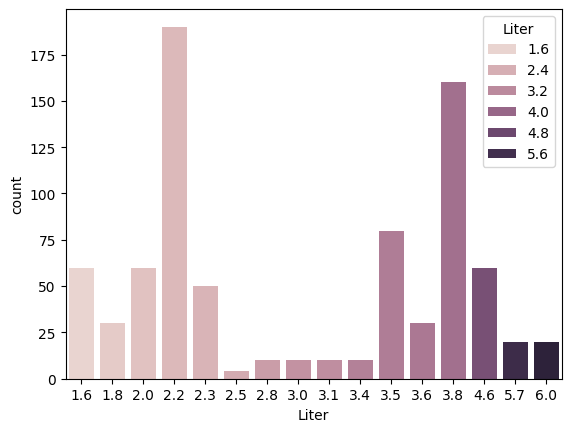

In [50]:
sns.countplot(x=df['Liter'],hue=df['Liter']);

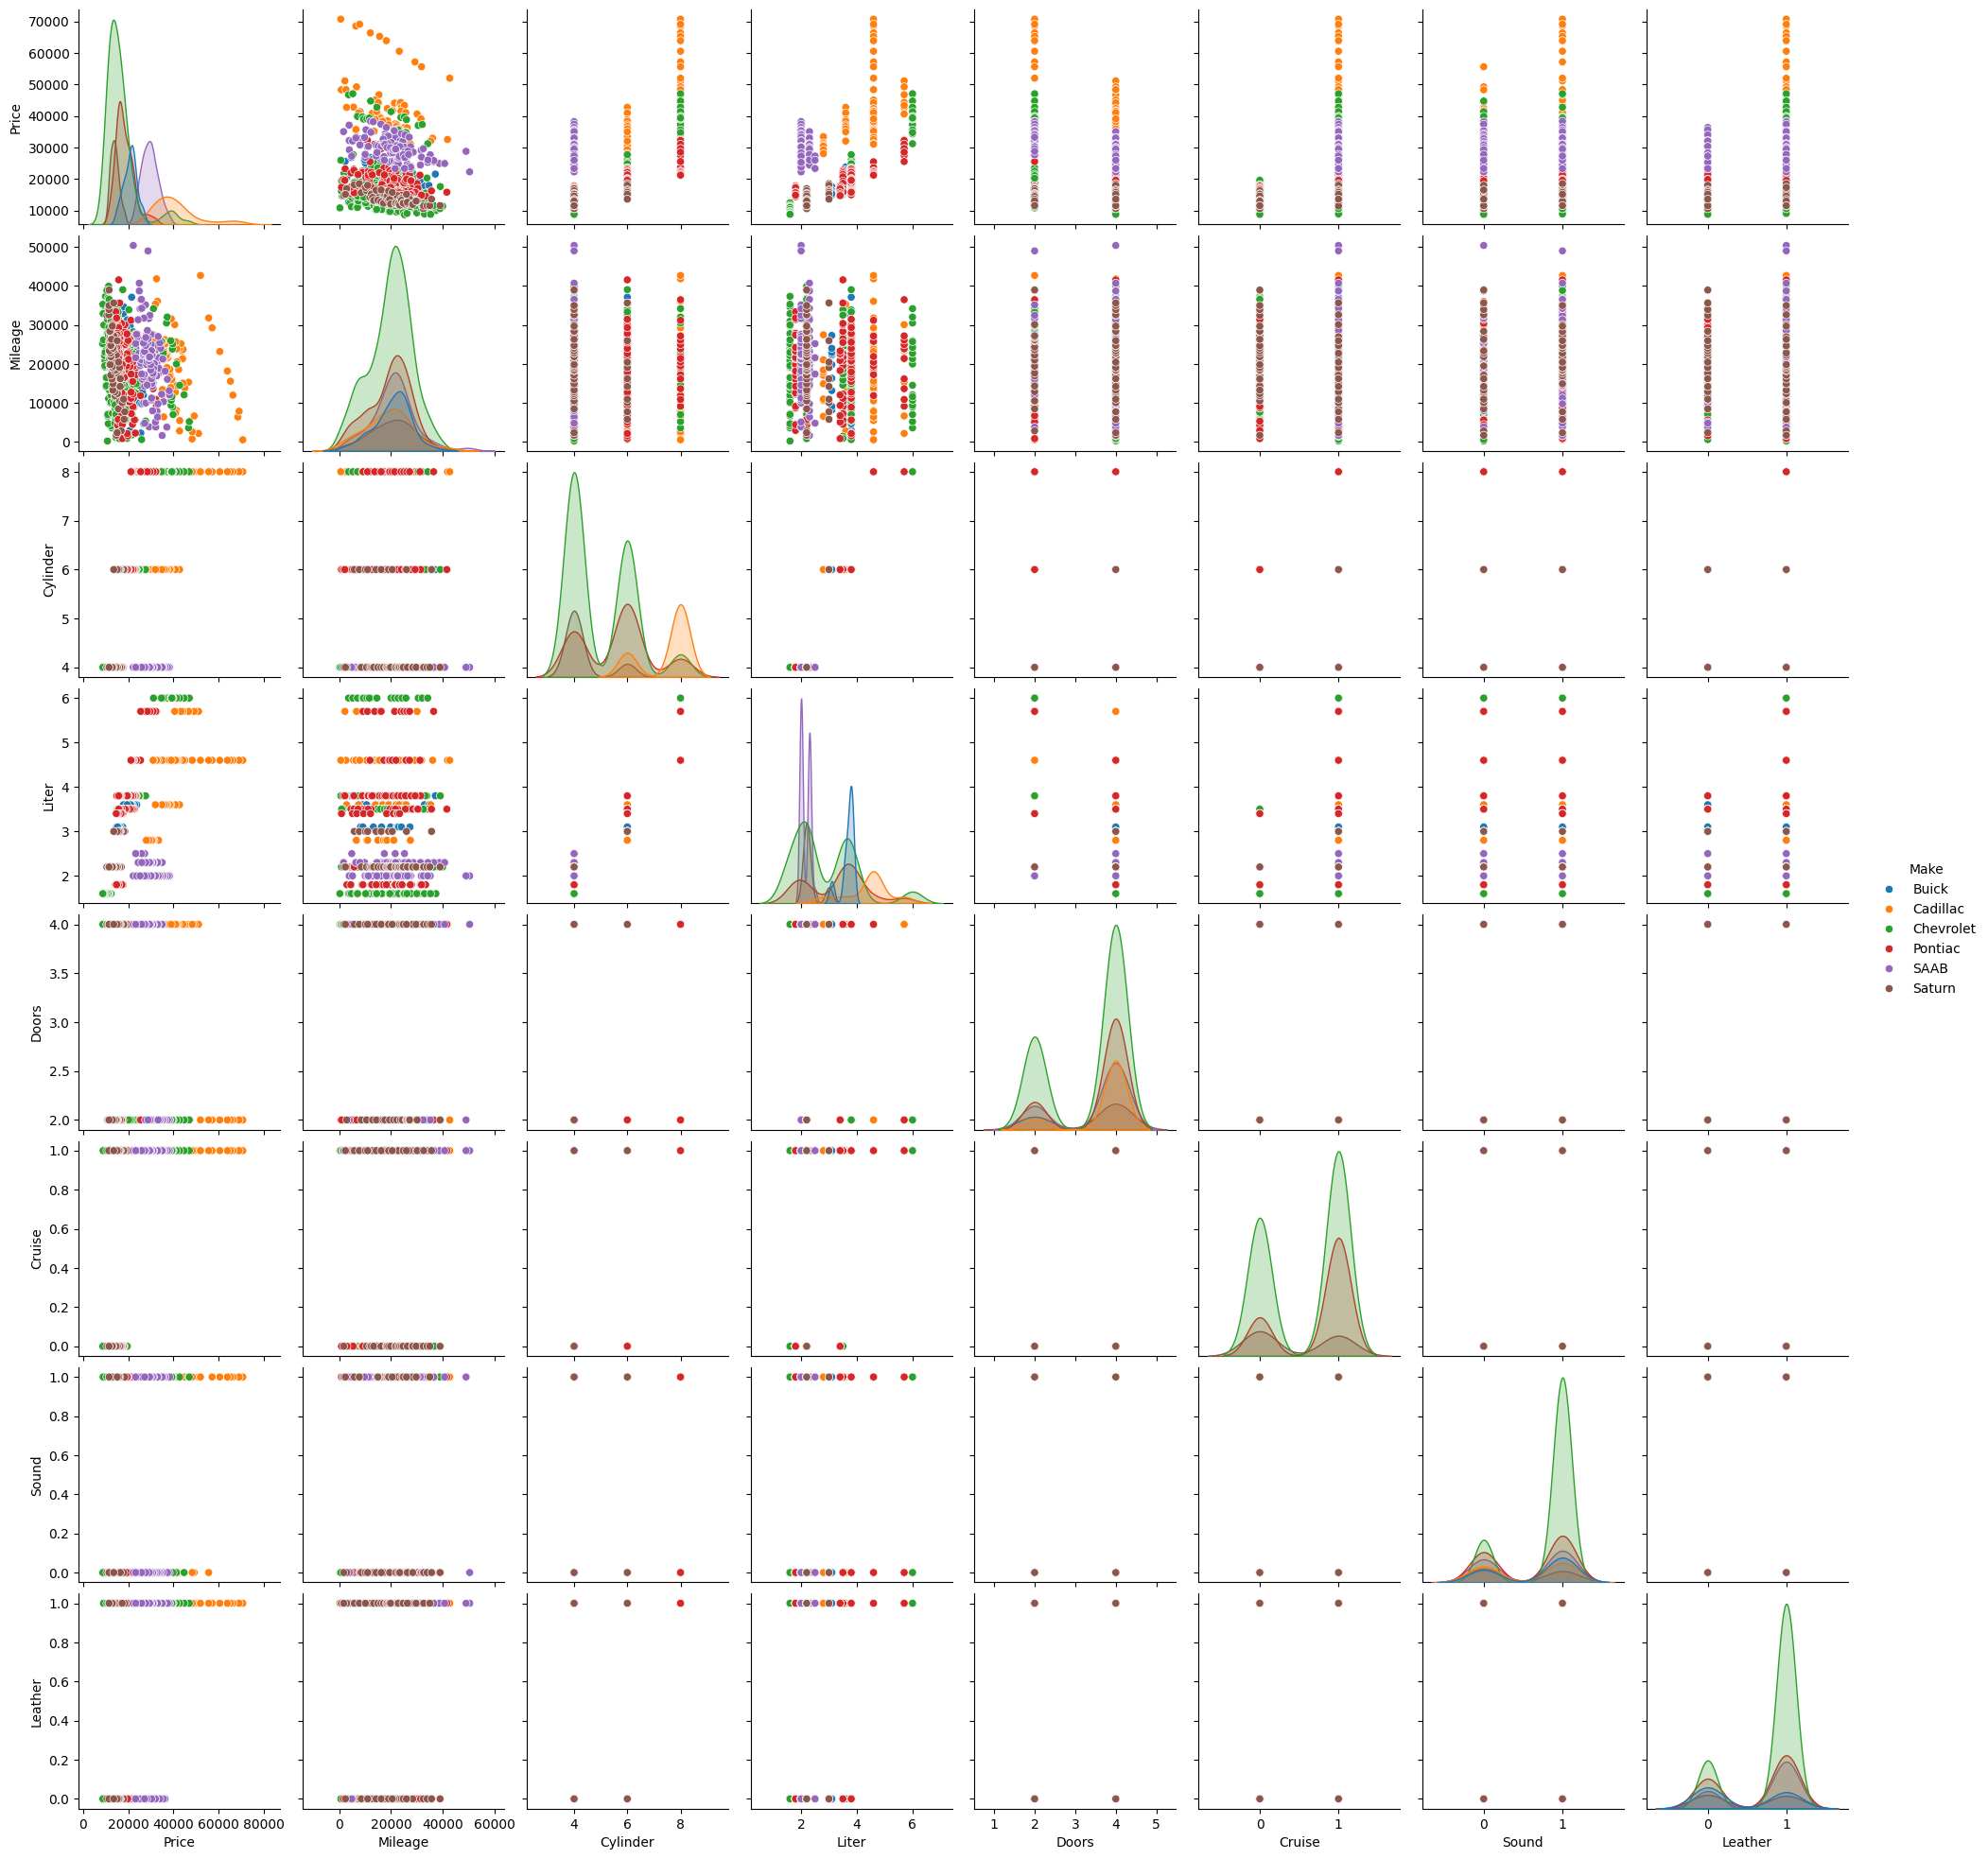

In [52]:
sns.pairplot(df,hue='Make');

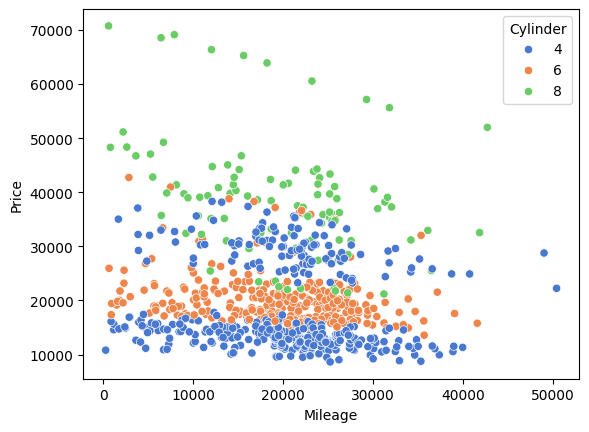

In [53]:
sns.scatterplot(x=df['Mileage'],y=df['Price'],hue=df['Cylinder'],palette='muted');

### P - Value Calculation

In [55]:
# Null Hypothesis
# H0: There is no relationship between the car's mileage and its price.
# HA: There is a relationship between the car's mileage and its price.
# Calculate the p-value.
# If p< 0.05, reject the null hypothesis in favor of the alternative hypothesis.
# If p>= 0.05, fail to reject the null hypothesis.

In [56]:
from scipy.stats import ttest_ind

In [58]:
t,p=ttest_ind(df['Price'],df['Mileage'])

In [59]:
float(p)

0.0008662338227446262

In [60]:
p<0.05

np.True_

In [62]:
#Result: There is a relationship between a car's mileage and its price. One affects the other, and the relationship is statistically significant.

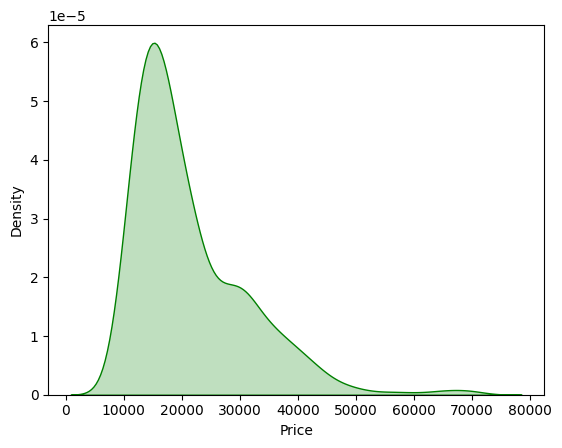

In [66]:
sns.kdeplot(x=df['Price'], fill=True ,color='green');

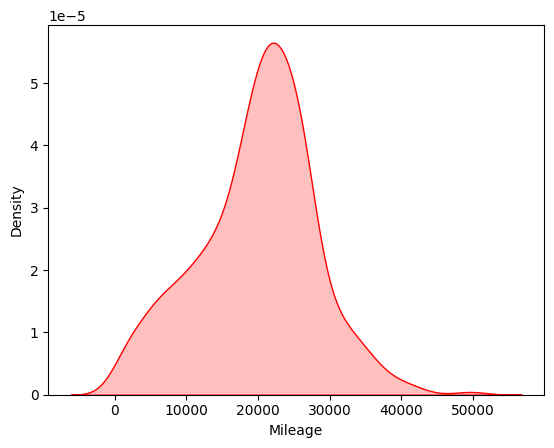

In [67]:
sns.kdeplot(x=df['Mileage'], fill=True ,color='red');

#### OUTLIER

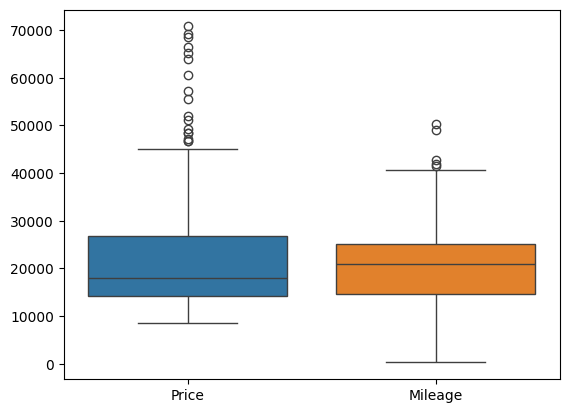

In [68]:
sns.boxplot([df['Price'],df['Mileage']]);

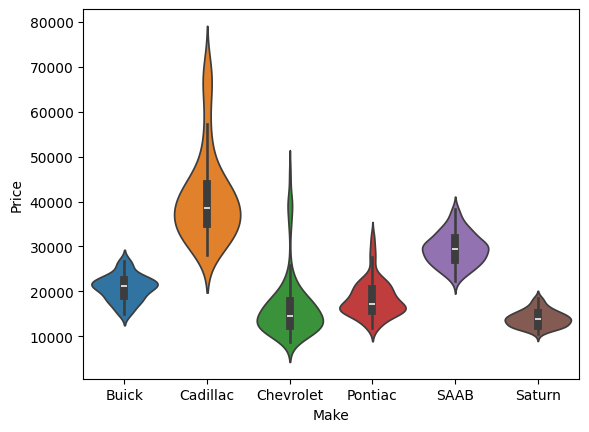

In [70]:
sns.violinplot(x='Make',y='Price',data=df,hue='Make');

In [71]:
import plotly.express as px

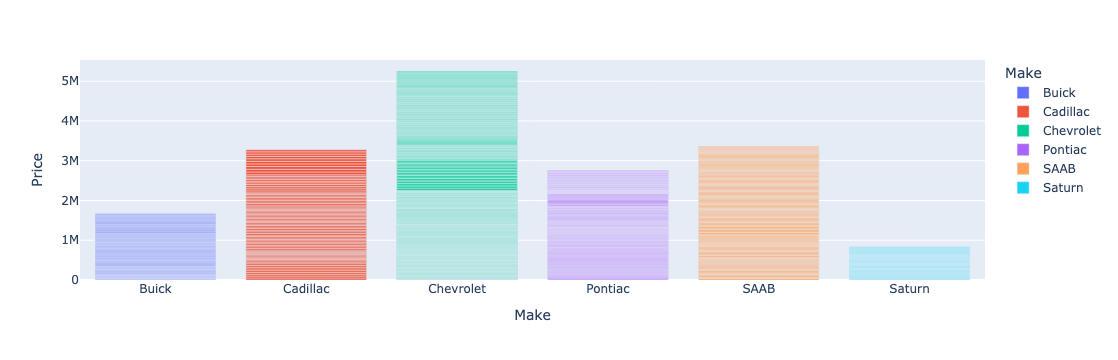

In [72]:
px.bar(df,x='Make',y='Price',color='Make')

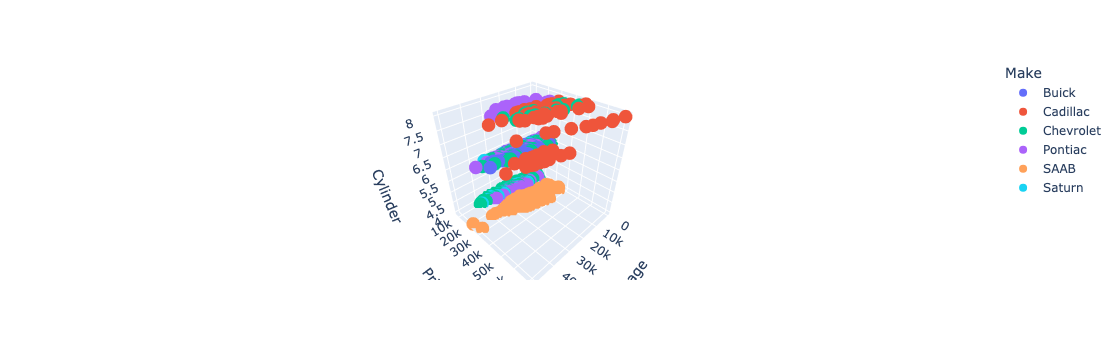

In [75]:
px.scatter_3d(df,x='Mileage',y='Price',color='Make',z='Cylinder')

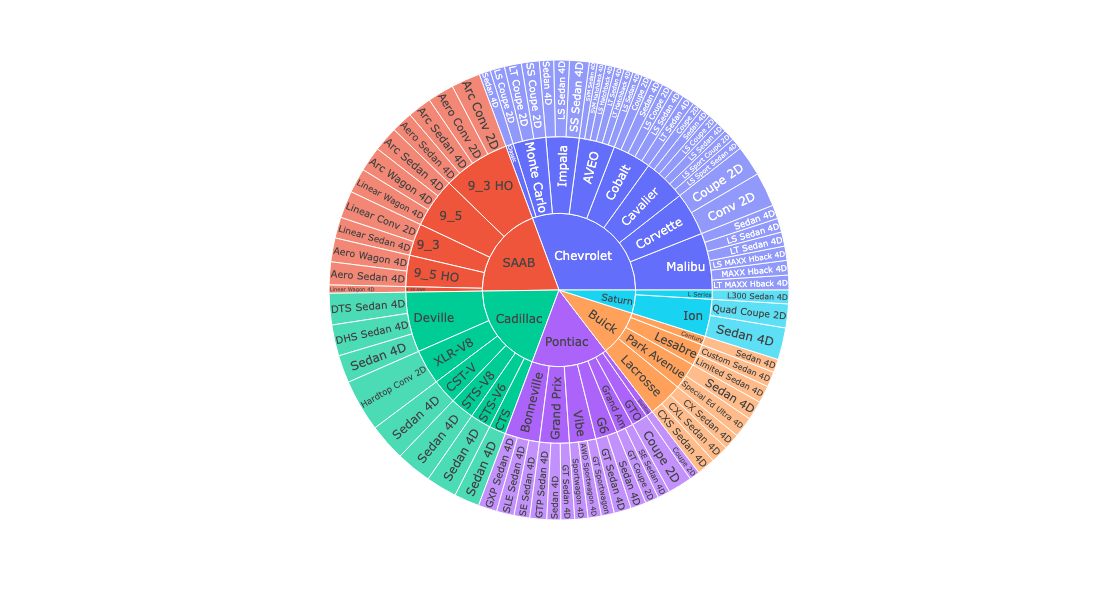

In [76]:
px.sunburst(df,path=['Make','Model','Trim'],values='Price',width=800,height=600)

### Feature Engineering

In [79]:
#Regression GOLDEN RULE:
#We select features with a correlation greater than 0.20 and less than 0.90.
#If the correlation is greater than 0.90, the features may contain redundant information.
#We generally avoid using highly correlated features together because they may provide overlapping information.
#A correlation below 0.20 indicates a weak relationship and may contribute very little to the model.

In [80]:
df.corr(numeric_only=True)

,Price,Mileage,Cylinder,Liter,Doors,Cruise,Sound,Leather
Price,1.000000,-0.143051,0.569086,0.558146,-0.138750,0.430851,-0.124348,0.157197
Mileage,-0.143051,1.000000,-0.029461,-0.018641,-0.016944,0.025037,-0.026146,0.001005
Cylinder,0.569086,-0.029461,1.000000,0.957897,0.002206,0.354285,-0.089704,0.075520
Liter,0.558146,-0.018641,0.957897,1.000000,-0.079259,0.377509,-0.065527,0.087332
Doors,-0.138750,-0.016944,0.002206,-0.079259,1.000000,-0.047674,-0.062530,-0.061969
Cruise,0.430851,0.025037,0.354285,0.377509,-0.047674,1.000000,-0.091730,-0.070573
Sound,-0.124348,-0.026146,-0.089704,-0.065527,-0.062530,-0.091730,1.000000,0.165444
Leather,0.157197,0.001005,0.075520,0.087332,-0.061969,-0.070573,0.165444,1.000000


In [82]:
abs(df.corr(numeric_only=True))['Price'].sort_values(ascending=False)

Price       1.000000
Cylinder    0.569086
Liter       0.558146
Cruise      0.430851
Leather     0.157197
Mileage     0.143051
Doors       0.138750
Sound       0.124348
Name: Price, dtype: float64

### Modelling

In [85]:
x=df[['Mileage','Cylinder','Liter','Cruise']] #domain information is very important
y=df[['Price']]

In [86]:
from sklearn.model_selection import train_test_split

In [88]:
x_train,x_test,y_train,y_test=train_test_split(x,y, random_state=42, test_size=.20)

In [89]:
df.shape

(804, 12)

In [90]:
x_train.shape,x_test.shape

((643, 4), (161, 4))

In [91]:
from sklearn.linear_model import LinearRegression

In [92]:
Lr=LinearRegression()

In [93]:
model=Lr.fit(x_train,y_train)

In [94]:
pred=model.predict(x_test)

In [95]:
from sklearn.metrics import r2_score, mean_squared_error

In [96]:
r2_score(y_test,pred) # Accuracy

0.3071114906997997

In [97]:
mean_squared_error(y_test,pred)**.5 # Error rate

7413.255792158803

In [99]:
x=df[['Mileage','Cylinder','Liter','Cruise','Make','Model','Trim']]
y=df[['Price']]

In [102]:
x=pd.get_dummies(x,drop_first=True)

In [103]:
x.head()

,Mileage,Cylinder,Liter,Cruise,Make_Cadillac,Make_Chevrolet,Make_Pontiac,Make_SAAB,Make_Saturn,Model_9_3,...,Trim_Quad Coupe 2D,Trim_SE Sedan 4D,Trim_SLE Sedan 4D,Trim_SS Coupe 2D,Trim_SS Sedan 4D,Trim_SVM Hatchback 4D,Trim_SVM Sedan 4D,Trim_Sedan 4D,Trim_Special Ed Ultra 4D,Trim_Sportwagon 4D
0,8221,6,3.1,1,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,9135,6,3.1,1,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,13196,6,3.1,1,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,16342,6,3.1,1,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,19832,6,3.1,1,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [104]:
x_train,x_test,y_train,y_test=train_test_split(x,y, random_state=42, test_size=.20) #seed=random_state=42

In [105]:
model=Lr.fit(x_train,y_train)

In [106]:
pred=model.predict(x_test)

In [107]:
r2_score(y_test,pred) # Accuracy

0.99118854677259

In [108]:
mean_squared_error(y_test,pred)**.5 # Error rate ($835)

835.9899877493722

In [109]:
comp=pd.DataFrame()

In [110]:
comp['Price']=y_test
comp['Pred']=pred

In [112]:
comp.head()

,Price,Pred
192,11302.902985,11931.572448
717,29114.544506,29589.064196
168,10777.052537,9679.382185
522,20677.593819,20806.642631
536,15253.868566,14979.560535


In [113]:
from sklearn.linear_model import Ridge,Lasso,ElasticNet

In [114]:
R=Ridge() #Regularization hatanin karesinin karekoku
L=Lasso() #hatalarin mutlak degerini alir
EN=ElasticNet() #Ridge ve Lassonun iyi olan kisimlarini alir

In [115]:
R.fit(x_train,y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [116]:
Rped=R.predict(x_test)

In [117]:
r2_score(y_test,pred)

0.99118854677259

In [118]:
L.fit(x_train,y_train)

/Users/nbarcin/anaconda3/envs/yeni_env/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.458e+08, tolerance: 6.560e+06



,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [119]:
Lped=R.predict(x_test)

In [120]:
r2_score(y_test,pred)

0.99118854677259

In [121]:
model.coef_  # herbir sutundan makinenin turev  alarak ogrendigi katsayi

array([[-1.87571841e-01,  1.36860561e+03,  3.08314289e+03,
         7.84875187e+01,  1.15176391e+04, -2.48135940e+03,
        -2.89930092e+03,  6.36955149e+03, -2.10392446e+03,
         4.12852724e+03,  6.05231464e+03,  6.63055612e+03,
         7.21257302e+03, -7.45789358e+02, -3.13507284e+03,
         1.85966337e+03, -1.27472619e+03, -3.00730126e+02,
        -4.73165605e+03,  1.22437809e+03,  6.90594323e+02,
         6.35817207e+03, -6.59630401e+03,  2.54379654e+02,
         9.14792713e+02, -1.21055437e+03, -3.26414168e+03,
        -2.70201960e+03,  1.07784144e+02, -2.21170860e+03,
        -2.48153670e+03, -3.44518392e+03, -3.09949698e+03,
        -3.90646783e+03,  2.55770818e+02,  3.88996075e+03,
         3.23561220e+03,  3.20892578e+02,  3.22040303e+03,
         1.04034330e+04,  3.05921890e+03, -3.43187911e+03,
        -2.01040581e+03,  6.14896102e+03, -7.46102144e+02,
        -1.46134873e+01, -1.94969865e+03, -6.29582087e+02,
         9.77440324e+01,  2.89107027e+03, -2.24546993e+0

In [122]:
L.coef_

array([-1.87197421e-01,  1.57297614e+03,  2.45865187e+03,  8.16757049e+01,
        1.67503085e+04, -8.53166740e+02, -4.96293114e+02,  1.02228665e+04,
       -0.00000000e+00,  1.78510032e+03,  4.28854147e+03,  5.34922136e+03,
        5.12893442e+03, -7.92502027e+02, -1.28039747e+03, -0.00000000e+00,
       -4.46854760e+03, -0.00000000e+00, -2.50652028e+03,  1.51685337e+03,
        9.96770325e+02,  8.18033193e+03, -8.94234666e+03,  1.68068452e+02,
        1.70283290e+03, -1.10606218e+01, -3.03383886e+03, -1.68969221e+03,
        0.00000000e+00, -3.15926503e+03,  2.94188581e+02, -0.00000000e+00,
       -2.37691150e+03, -2.71374340e+03,  2.83827805e+03,  1.03501834e+03,
        6.11711522e+02, -7.92628624e+01,  3.41683767e+03,  1.91257905e+04,
        3.85454883e+03, -2.23384369e+03, -5.47898998e+02,  6.94214794e+03,
       -0.00000000e+00,  4.73547040e+02, -1.09995797e+03,  7.07506063e+01,
        8.93703101e+02,  4.02224646e+03, -1.05022449e+03, -2.91802114e+03,
        3.11148131e+03,  

In [124]:
#For a regression model to be considered successful:
#R² should be high.
#RMSE should be low.
#Residuals should follow an approximately normal distribution.

In [125]:
# feature importance

In [126]:
fi=pd.DataFrame({'Feature':x_train.columns,'coef':model.coef_[0]})

In [127]:
fi

,Feature,coef
0,Mileage,-0.187572
1,Cylinder,1368.605609
2,Liter,3083.142889
3,Cruise,78.487519
4,Make_Cadillac,11517.639143
...,...,...
81,Trim_SVM Hatchback 4D,-3357.779669
82,Trim_SVM Sedan 4D,-1996.070103
83,Trim_Sedan 4D,-2356.053212
84,Trim_Special Ed Ultra 4D,-575.046151


<BarContainer object of 86 artists>

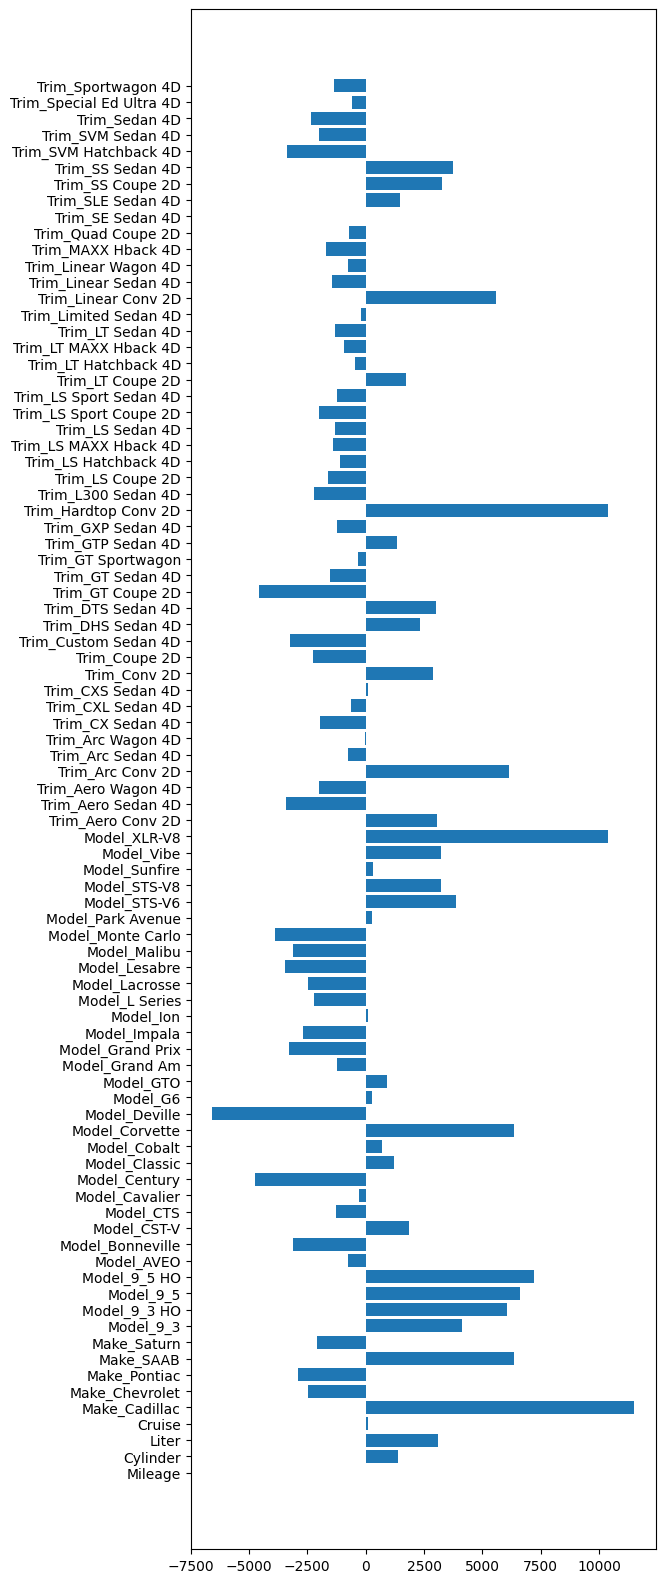

In [128]:
plt.figure(figsize=(6,20))
plt.barh(fi['Feature'],fi['coef'])

In [129]:
residuals=y_test-pred

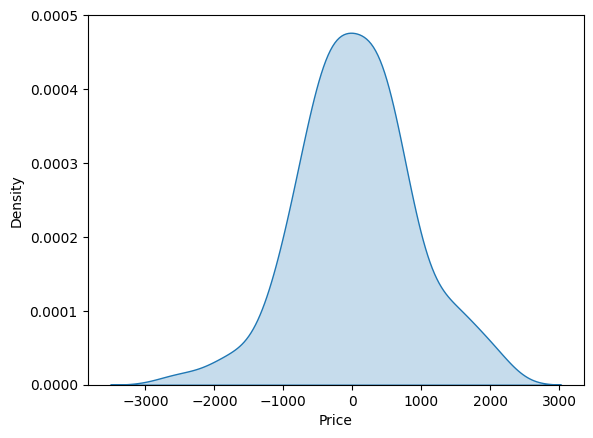

In [130]:
sns.kdeplot(x=residuals['Price'],fill=True);

### Data Normalization

<img src=https://cdn.educba.com/academy/wp-content/uploads/2019/05/Normalization-Formula.jpg width=400>

In [141]:
from sklearn.preprocessing import MinMaxScaler

In [142]:
x=MinMaxScaler().fit_transform(x)

In [143]:
x_train,x_test,y_train,y_test=train_test_split(x,y, random_state=42, test_size=.20)

In [144]:
Lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [145]:
pred=model.predict(x_test)

In [146]:
r2_score(y_test,pred)

0.9911885467725908

In [147]:
EN.fit(x_train,y_train)

,alpha,1.0
,l1_ratio,0.5
,fit_intercept,True
,precompute,False
,max_iter,1000
,copy_X,True
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [148]:
ENpred=EN.predict(x_test)

In [149]:
r2_score(y_test,ENpred)

0.4809969577121197

In [150]:
from sklearn.tree import DecisionTreeRegressor

In [151]:
dt=DecisionTreeRegressor()

In [152]:
dt.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [153]:
dtpred=dt.predict(x_test)

In [155]:
r2_score(y_test,dtpred)

0.9743672934465281

In [156]:
from sklearn.tree import plot_tree

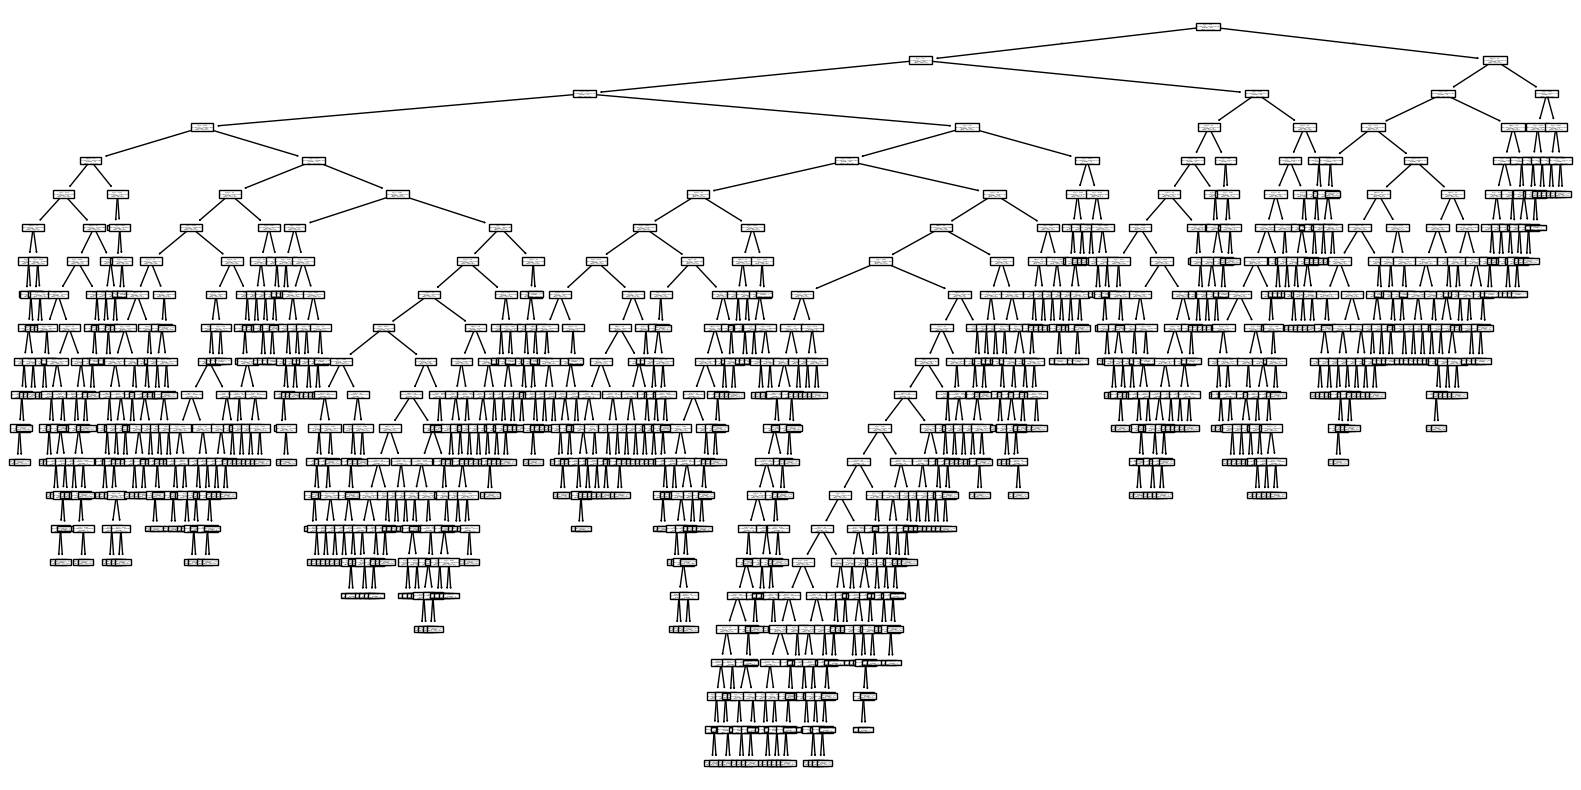

In [157]:
plt.figure(figsize=(20,10))
plot_tree(dt); # plt.savefig('decision_tree')

In [158]:
from sklearn.ensemble import ExtraTreesRegressor

In [159]:
ET=ExtraTreesRegressor()

In [160]:
ET.fit(x_train,y_train)

/Users/nbarcin/anaconda3/envs/yeni_env/lib/python3.10/site-packages/sklearn/base.py:1365: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [161]:
ETpred=ET.predict(x_test)

In [162]:
r2_score(y_test,ETpred)

0.9940444477209808

In [164]:
%%capture
!pip install xgboost
!pip install catboost

In [167]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error

# Linear / Regularized
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  SGDRegressor, HuberRegressor, RANSACRegressor,
                                  BayesianRidge, OrthogonalMatchingPursuit)
# Tree
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, AdaBoostRegressor)
# Neighbors
from sklearn.neighbors import KNeighborsRegressor
# SVR / Kernel
from sklearn.svm import SVR, NuSVR
from sklearn.kernel_ridge import KernelRidge
# Neural Net
from sklearn.neural_network import MLPRegressor
# Boosting
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Yellowbrick
from yellowbrick.regressor import PredictionError, ResidualsPlot

# Suppress warnings
warnings.filterwarnings("ignore")

def algo_test(x, y, plot=True, yellowbrick_viz=False):
    # ======================
    # Define Regression Models
    # ======================
    algos = [
        LinearRegression(),
        Ridge(),
        Lasso(),
        ElasticNet(),
        SGDRegressor(max_iter=1000, tol=1e-3),
        HuberRegressor(),
        RANSACRegressor(),
        BayesianRidge(),
        OrthogonalMatchingPursuit(),
        ExtraTreeRegressor(),
        DecisionTreeRegressor(),
        RandomForestRegressor(),
        GradientBoostingRegressor(),
        HistGradientBoostingRegressor(),
        AdaBoostRegressor(),
        XGBRegressor(verbosity=0, n_jobs=-1),
        CatBoostRegressor(verbose=0),
        KNeighborsRegressor(),
        SVR(),
        NuSVR(),
        KernelRidge(),
        MLPRegressor(max_iter=500, hidden_layer_sizes=(100,50))
    ]

    algo_names = [
        'Linear', 'Ridge', 'Lasso', 'ElasticNet', 'SGD', 
        'Huber', 'RANSAC', 'BayesianRidge', 'OMP',
        'Extra Tree', 'Decision Tree', 'Random Forest', 'Gradient Boosting',
        'HistGradientBoosting', 'AdaBoost', 'XGBoost', 'CatBoost',
        'KNN', 'SVR', 'NuSVR', 'KernelRidge', 'MLP'
    ]

    # ======================
    # Train/Test Split
    # ======================
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.20, random_state=42
    )

    results = []

    # ======================
    # Fit Models & Evaluate
    # ======================
    for name, algo in zip(algo_names, algos):
        try:
            # Scale only non-tree models
            if name not in ['Extra Tree', 'Decision Tree', 'Random Forest',
                            'Gradient Boosting', 'HistGradientBoosting',
                            'AdaBoost', 'XGBoost', 'CatBoost']:
                scaler = MinMaxScaler()
                x_train_scaled = scaler.fit_transform(x_train)
                x_test_scaled = scaler.transform(x_test)
            else:
                x_train_scaled = x_train
                x_test_scaled = x_test

            # Fit and predict
            preds = algo.fit(x_train_scaled, y_train).predict(x_test_scaled)
            r2 = r2_score(y_test, preds)
            rmse = mean_squared_error(y_test, preds)
        except Exception as e:
            r2 = None
            rmse = None
            print(f"Model {name} failed: {e}")

        results.append({
            "Model": name,
            "R2": r2,
            "RMSE": rmse
        })

        # ======================
        # Yellowbrick visualizations
        # ======================
        if yellowbrick_viz:
            try:
                # Prediction Error
                plt.figure(figsize=(10, 6))
                visualizer = PredictionError(algo)
                visualizer.fit(x_train_scaled, y_train)
                visualizer.score(x_test_scaled, y_test)
                visualizer.show()

                # Residuals Plot
                plt.figure(figsize=(10, 6))
                visualizer = ResidualsPlot(algo)
                visualizer.fit(x_train_scaled, y_train)
                visualizer.score(x_test_scaled, y_test)
                visualizer.show()

            except Exception as e:
                print(f"Yellowbrick visualizations for {name} failed: {e}")

    # ======================
    # Results Table
    # ======================
    result_df = pd.DataFrame(results).sort_values("R2", ascending=False)
    
    print("\n=== Regression Model Comparison ===\n")
    print(result_df.reset_index(drop=True))

    # ======================
    # Seaborn Plots
    # ======================
    if plot:
        plt.figure(figsize=(18, 7))

        # R2 Score
        plt.subplot(1, 2, 1)
        sns.barplot(data=result_df, x="Model", y="R2", palette="viridis")
        plt.title("R² Score Comparison (Higher is Better)")
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis="y", alpha=0.3)

        # RMSE
        plt.subplot(1, 2, 2)
        sns.barplot(data=result_df, x="Model", y="RMSE", palette="magma")
        plt.title("RMSE Comparison (Lower is Better)")
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()

        # RMSE vs R2 scatter
        plt.figure(figsize=(12, 6))
        sns.scatterplot(data=result_df, x="RMSE", y="R2", hue="Model", s=150)
        for i, row in result_df.iterrows():
            plt.text(row["RMSE"], row["R2"], row["Model"], fontsize=9)
        plt.title("Regression Model Trade-off: RMSE vs R²")
        plt.xlabel("RMSE (Lower is Better)")
        plt.ylabel("R² (Higher is Better)")
        plt.grid(alpha=0.3)
        plt.show()

    return result_df


=== Regression Model Comparison ===

                   Model        R2          RMSE
0               CatBoost  0.995453  3.606245e+05
1                  Huber  0.991551  6.701094e+05
2                  Lasso  0.991278  6.917820e+05
3          BayesianRidge  0.991273  6.921746e+05
4                 Linear  0.991189  6.988793e+05
5                    SGD  0.990061  7.883304e+05
6                XGBoost  0.989899  8.011239e+05
7                  Ridge  0.989471  8.350965e+05
8          Random Forest  0.987010  1.030308e+06
9             Extra Tree  0.986588  1.063769e+06
10           KernelRidge  0.985298  1.166112e+06
11     Gradient Boosting  0.981503  1.467078e+06
12                   KNN  0.978541  1.702044e+06
13                RANSAC  0.977965  1.747700e+06
14         Decision Tree  0.975523  1.941379e+06
15  HistGradientBoosting  0.955434  3.534757e+06
16                   OMP  0.910628  7.088519e+06
17              AdaBoost  0.877080  9.749385e+06
18                   MLP  0.869

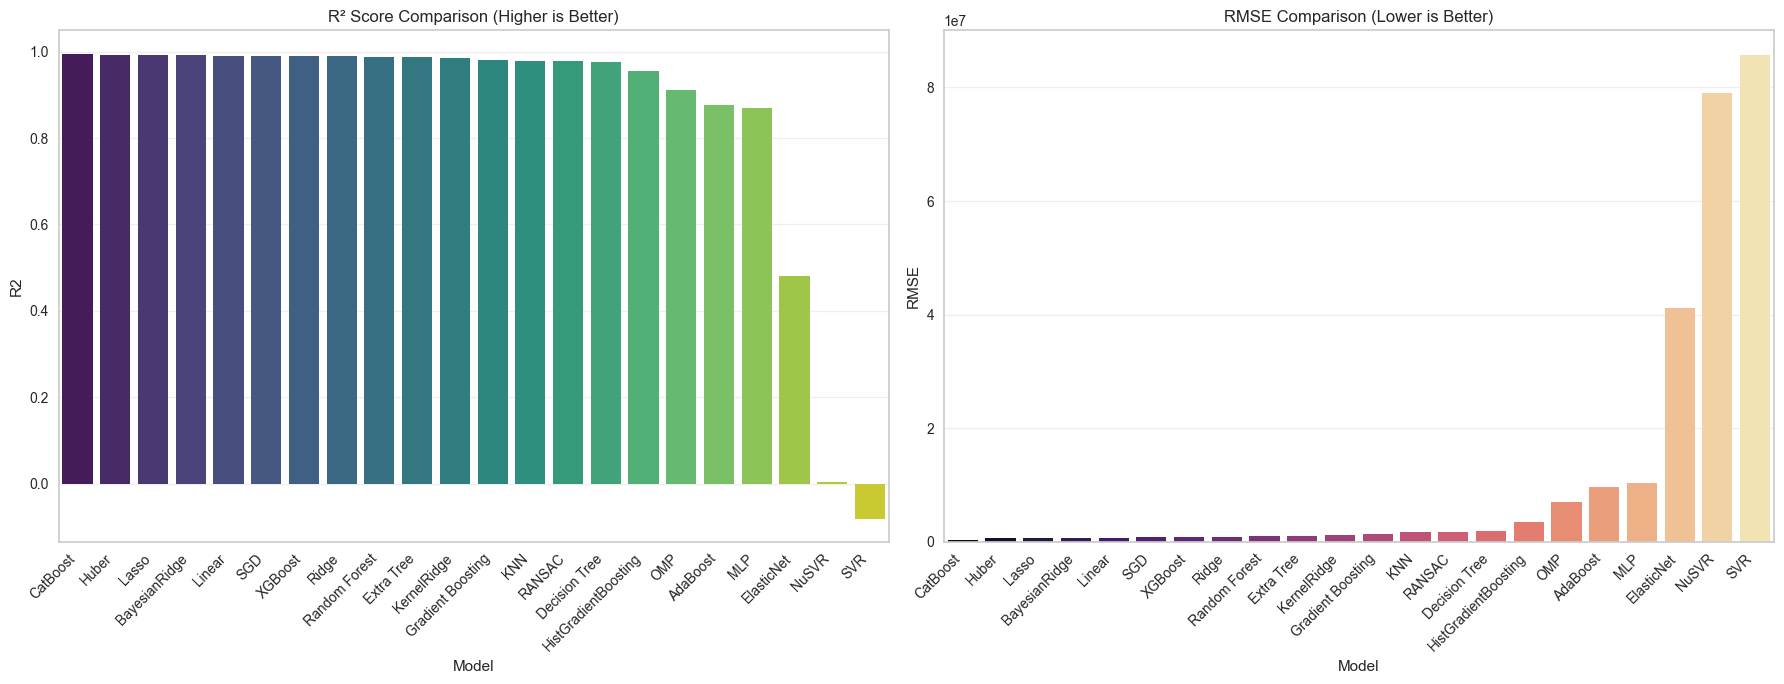

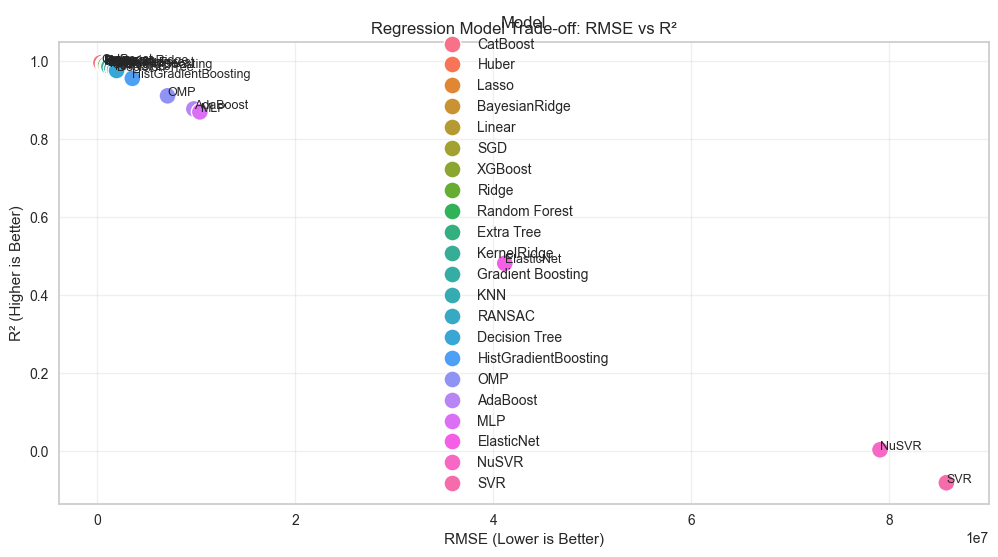

,Model,R2,RMSE
16,CatBoost,0.995453,3.606245e+05
5,Huber,0.991551,6.701094e+05
2,Lasso,0.991278,6.917820e+05
7,BayesianRidge,0.991273,6.921746e+05
0,Linear,0.991189,6.988793e+05
4,SGD,0.990061,7.883304e+05
15,XGBoost,0.989899,8.011239e+05
1,Ridge,0.989471,8.350965e+05
11,Random Forest,0.987010,1.030308e+06
9,Extra Tree,0.986588,1.063769e+06


In [168]:
algo_test(x,y)

In this course, we learned about regression models. CatBoost achieved the best results in predicting car prices, with an R² score of 99.54%. We successfully exceeded our target of 85%.